
DATASET INFORMATION
Middle  Rows =  903000 Duration =   903.32s Rate =   999.65 Hz
Ring    Rows =  903000 Duration =   903.42s Rate =   999.53 Hz
Thumb   Rows =  903000 Duration =   903.33s Rate =   999.64 Hz
Index   Rows =  903000 Duration =   903.27s Rate =   999.70 Hz
Little  Rows =  903000 Duration =   903.41s Rate =   999.54 Hz

CHANNEL QUALITY

Middle
EMG1 zero: 69.88%
EMG2 zero: 95.62%
EMG1 max: 862
EMG2 max: 1023
EMG1 at 1023: 0.0000%
EMG2 at 1023: 0.0016%

Ring
EMG1 zero: 61.88%
EMG2 zero: 65.69%
EMG1 max: 1023
EMG2 max: 1023
EMG1 at 1023: 0.0019%
EMG2 at 1023: 0.0004%

Thumb
EMG1 zero: 83.70%
EMG2 zero: 80.38%
EMG1 max: 1023
EMG2 max: 1023
EMG1 at 1023: 0.0001%
EMG2 at 1023: 1.2467%

Index
EMG1 zero: 67.82%
EMG2 zero: 100.00%
EMG1 max: 690
EMG2 max: 0
EMG1 at 1023: 0.0000%
EMG2 at 1023: 0.0000%

Little
EMG1 zero: 62.49%
EMG2 zero: 41.18%
EMG1 max: 1023
EMG2 max: 1023
EMG1 at 1023: 0.0009%
EMG2 at 1023: 0.0004%

WINDOW CREATION
Middle (4515, 20)
Ring (4515, 20)
Thumb (4515, 2

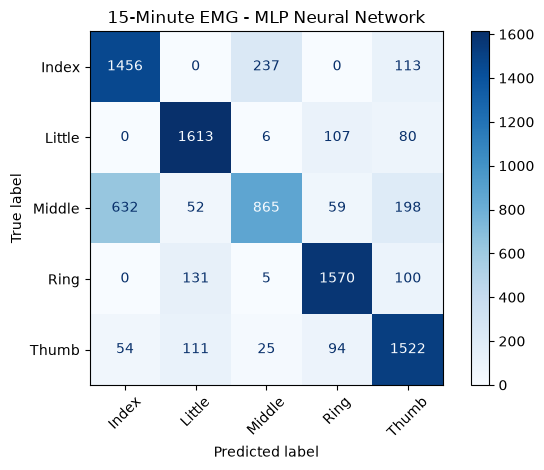

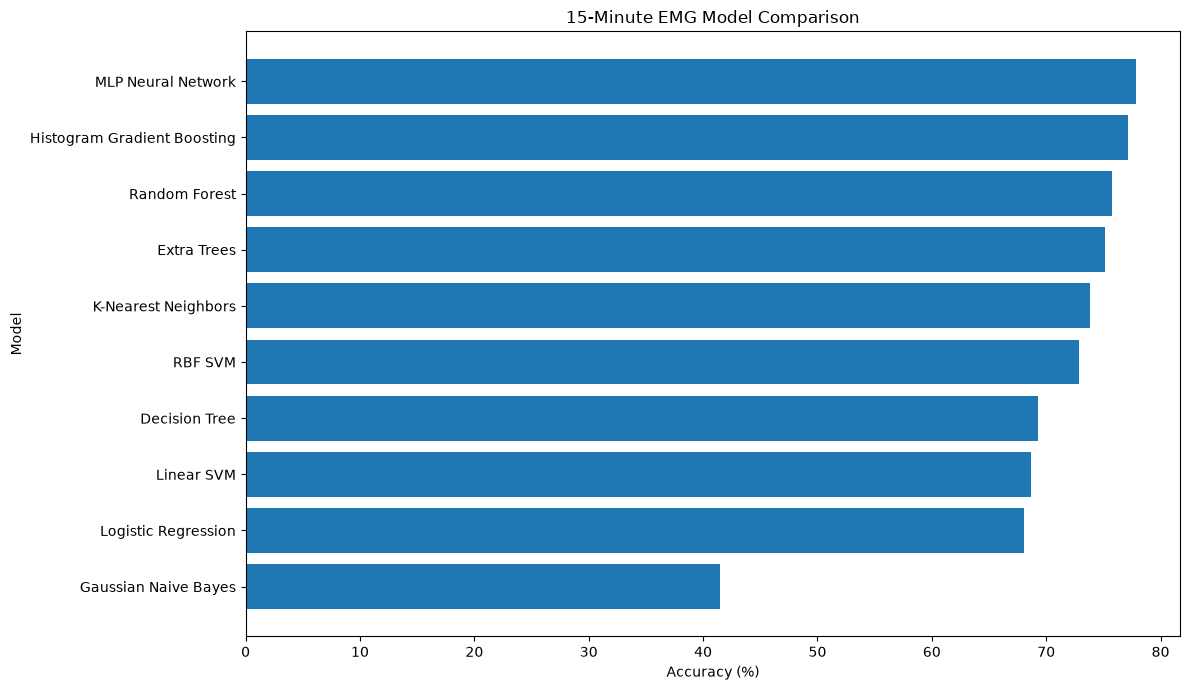


RANDOM WINDOW PREDICTIONS
Actual: Index
Logistic Regression            Index
K-Nearest Neighbors            Index
RBF SVM                        Index
Linear SVM                     Index
Decision Tree                  Middle
Random Forest                  Index
Extra Trees                    Index
Histogram Gradient Boosting    Index
Gaussian Naive Bayes           Index
MLP Neural Network             Index

Random Forest Feature Importance
                 Feature  Importance
    EMG1_Waveform_Length    0.097513
               EMG1_Mean    0.086331
EMG1_Mean_Absolute_Value    0.084674
 EMG1_Standard_Deviation    0.070995
                EMG1_RMS    0.068293
           EMG1_Variance    0.067596
            EMG2_Maximum    0.055307
               EMG2_Mean    0.054443
           EMG2_Variance    0.051925
              EMG1_Range    0.051163
              EMG2_Range    0.050760
                EMG2_RMS    0.049640
    EMG2_Waveform_Length    0.048234
EMG2_Mean_Absolute_Value    0.048134

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")


middle = pd.read_csv(
    "../EMG Recordings/middle_finger_15mins.csv"
)

ring = pd.read_csv(
    "../EMG Recordings/ring_finger_15mins.csv"
)

thumb = pd.read_csv(
    "../EMG Recordings/thumb_finger_15mins.csv"
)

index = pd.read_csv(
    "../EMG Recordings/index_finger_15mins.csv"
)

little = pd.read_csv(
    "../EMG Recordings/little_finger_15mins.csv"
)


ROWS_PER_FINGER = 903000
WINDOW_SIZE = 200


recordings = {
    "Middle": middle.head(ROWS_PER_FINGER),
    "Ring": ring.head(ROWS_PER_FINGER),
    "Thumb": thumb.head(ROWS_PER_FINGER),
    "Index": index.head(ROWS_PER_FINGER),
    "Little": little.head(ROWS_PER_FINGER)
}


print("\nDATASET INFORMATION")

for finger, data in recordings.items():

    duration = (
        data["time_s"].iloc[-1]
        -
        data["time_s"].iloc[0]
    )

    sample_rate = (
        (len(data) - 1)
        /
        duration
    )

    print(
        f"{finger:7} "
        f"Rows = {len(data):7} "
        f"Duration = {duration:8.2f}s "
        f"Rate = {sample_rate:8.2f} Hz"
    )


print("\nCHANNEL QUALITY")

for finger, data in recordings.items():

    emg1_zero = (
        data["emg1"].eq(0).mean() * 100
    )

    emg2_zero = (
        data["emg2"].eq(0).mean() * 100
    )

    emg1_max = data["emg1"].max()
    emg2_max = data["emg2"].max()

    emg1_saturation = (
        data["emg1"].eq(1023).mean() * 100
    )

    emg2_saturation = (
        data["emg2"].eq(1023).mean() * 100
    )

    print(
        f"\n{finger}"
    )

    print(
        f"EMG1 zero: {emg1_zero:.2f}%"
    )

    print(
        f"EMG2 zero: {emg2_zero:.2f}%"
    )

    print(
        f"EMG1 max: {emg1_max}"
    )

    print(
        f"EMG2 max: {emg2_max}"
    )

    print(
        f"EMG1 at 1023: "
        f"{emg1_saturation:.4f}%"
    )

    print(
        f"EMG2 at 1023: "
        f"{emg2_saturation:.4f}%"
    )


def calculate_statistics(values):

    values = values.astype(float)

    mean_value = np.mean(values)

    median_value = np.median(values)

    minimum_value = np.min(values)

    maximum_value = np.max(values)

    standard_deviation = np.std(values)

    variance_value = np.var(values)

    value_range = (
        maximum_value
        -
        minimum_value
    )

    rms_value = np.sqrt(
        np.mean(
            values ** 2
        )
    )

    mean_absolute_value = np.mean(
        np.abs(values)
    )

    waveform_length = np.sum(
        np.abs(
            np.diff(values)
        )
    )

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]


statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]


feature_names = []

for name in statistic_names:

    feature_names.append(
        f"EMG1_{name}"
    )

for name in statistic_names:

    feature_names.append(
        f"EMG2_{name}"
    )


def create_windows(
    data,
    window_size=200
):

    signals = data[
        ["emg1", "emg2"]
    ].values

    windows = []

    number_of_complete_rows = (
        len(signals)
        //
        window_size
    ) * window_size

    signals = signals[
        :number_of_complete_rows
    ]

    for start in range(
        0,
        len(signals),
        window_size
    ):

        window = signals[
            start:
            start + window_size
        ]

        emg1_statistics = (
            calculate_statistics(
                window[:, 0]
            )
        )

        emg2_statistics = (
            calculate_statistics(
                window[:, 1]
            )
        )

        features = np.concatenate(
            [
                emg1_statistics,
                emg2_statistics
            ]
        )

        windows.append(
            features
        )

    return np.array(
        windows
    )


emg_features = []

finger_labels = []


print("\nWINDOW CREATION")

for finger, data in recordings.items():

    finger_windows = create_windows(
        data,
        WINDOW_SIZE
    )

    print(
        finger,
        finger_windows.shape
    )

    for window in finger_windows:

        emg_features.append(
            window
        )

        finger_labels.append(
            finger
        )


emg_features = np.array(
    emg_features
)

finger_labels = np.array(
    finger_labels
)


print("\nFINAL FEATURE DATASET")

print(
    "Features:",
    emg_features.shape
)

print(
    "Labels:",
    finger_labels.shape
)

print(
    "Features per window:",
    emg_features.shape[1]
)

print(
    "\nClass distribution:"
)

print(
    pd.Series(
        finger_labels
    ).value_counts()
)


label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(
    finger_labels
)


print("\nLabel mapping")

for number, finger in enumerate(
    label_encoder.classes_
):

    print(
        number,
        "=",
        finger
    )


(
    train_features,
    test_features,
    train_labels,
    test_labels

) = train_test_split(

    emg_features,
    encoded_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    shuffle=True,

    stratify=encoded_labels
)


print(
    "\nTraining:",
    train_features.shape
)

print(
    "Testing:",
    test_features.shape
)


random_index = np.random.randint(
    0,
    len(test_features)
)

random_features = test_features[
    random_index
]

random_label_number = test_labels[
    random_index
]

random_label = label_encoder.inverse_transform(
    [random_label_number]
)[0]


print("\nRANDOM WINDOW")

print(
    "Actual finger:",
    random_label
)


print("\nStatistics")

print(
    f"{'Statistic':<25}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)


for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<25}"
        f"{random_features[i]:>15.4f}"
        f"{random_features[i + 10]:>15.4f}"
    )


models = {

    "Logistic Regression":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=3000,
                    random_state=42
                )
            )
        ]),

    "K-Nearest Neighbors":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                KNeighborsClassifier(
                    n_neighbors=7,
                    weights="distance",
                    n_jobs=-1
                )
            )
        ]),

    "RBF SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                SVC(
                    kernel="rbf",
                    C=3.0,
                    gamma="scale"
                )
            )
        ]),

    "Linear SVM":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LinearSVC(
                    C=1.0,
                    max_iter=5000,
                    random_state=42
                )
            )
        ]),

    "Decision Tree":

        DecisionTreeClassifier(
            min_samples_leaf=2,
            random_state=42
        ),

    "Random Forest":

        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Extra Trees":

        ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":

        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=300,
            max_leaf_nodes=31,
            random_state=42
        ),

    "Gaussian Naive Bayes":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                GaussianNB()
            )
        ]),

    "MLP Neural Network":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                MLPClassifier(
                    hidden_layer_sizes=(
                        128,
                        64
                    ),
                    max_iter=300,
                    early_stopping=False,
                    random_state=42
                )
            )
        ])
}


results = []

trained_models = {}

model_predictions = {}


print("\n")
print("=" * 70)
print("TRAINING 10 MODELS")
print("=" * 70)


for number, (
    model_name,
    model
) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{number}/10] "
        f"{model_name}"
    )

    try:

        start_time = time.perf_counter()

        model.fit(
            train_features,
            train_labels
        )

        training_time = (
            time.perf_counter()
            -
            start_time
        )

        start_time = time.perf_counter()

        predictions = model.predict(
            test_features
        )

        prediction_time = (
            time.perf_counter()
            -
            start_time
        )

        accuracy = accuracy_score(
            test_labels,
            predictions
        )

        balanced_accuracy = (
            balanced_accuracy_score(
                test_labels,
                predictions
            )
        )

        precision = precision_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            test_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            test_labels,
            predictions,
            average="weighted",
            zero_division=0
        )

        results.append(
            {
                "Model":
                    model_name,

                "Accuracy":
                    accuracy,

                "Balanced Accuracy":
                    balanced_accuracy,

                "Macro Precision":
                    precision,

                "Macro Recall":
                    recall,

                "Macro F1":
                    macro_f1,

                "Weighted F1":
                    weighted_f1,

                "Training Time":
                    training_time,

                "Prediction Time":
                    prediction_time
            }
        )

        trained_models[
            model_name
        ] = model

        model_predictions[
            model_name
        ] = predictions

        print(
            f"Accuracy: "
            f"{accuracy * 100:.2f}%"
        )

        print(
            f"Macro F1: "
            f"{macro_f1 * 100:.2f}%"
        )

        print(
            f"Training time: "
            f"{training_time:.2f}s"
        )

    except Exception as error:

        print(
            "FAILED:",
            error
        )


results = pd.DataFrame(
    results
)


results = results.sort_values(
    [
        "Accuracy",
        "Macro F1"
    ],
    ascending=False
).reset_index(
    drop=True
)


results.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(results) + 1
    )
)


display_results = results.copy()


for column in [
    "Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]:

    display_results[
        column
    ] *= 100


print("\n")
print("=" * 120)
print("MODEL COMPARISON")
print("=" * 120)


print(
    display_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)


results.to_csv(
    "15min_emg_model_comparison.csv",
    index=False
)


best_model_name = results.iloc[
    0
]["Model"]


best_model = trained_models[
    best_model_name
]


best_predictions = model_predictions[
    best_model_name
]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "Model:",
    best_model_name
)

print(
    f"Accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.2f}%"
)

print(
    f"Macro F1: "
    f"{results.iloc[0]['Macro F1'] * 100:.2f}%"
)


print("\nClassification Report\n")


print(
    classification_report(
        test_labels,
        best_predictions,
        labels=np.arange(
            len(label_encoder.classes_)
        ),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)


matrix = confusion_matrix(
    test_labels,
    best_predictions
)


display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=label_encoder.classes_
)


display.plot(
    cmap="Blues"
)


plt.title(
    f"15-Minute EMG - {best_model_name}"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


plot_results = results.sort_values(
    "Accuracy",
    ascending=True
)


plt.figure(
    figsize=(12, 7)
)


plt.barh(
    plot_results["Model"],
    plot_results["Accuracy"] * 100
)


plt.xlabel(
    "Accuracy (%)"
)

plt.ylabel(
    "Model"
)

plt.title(
    "15-Minute EMG Model Comparison"
)

plt.tight_layout()

plt.show()


print("\nRANDOM WINDOW PREDICTIONS")

print(
    "Actual:",
    random_label
)


for model_name, model in trained_models.items():

    prediction_number = model.predict(
        random_features.reshape(
            1,
            -1
        )
    )[0]

    predicted_finger = (
        label_encoder.inverse_transform(
            [prediction_number]
        )[0]
    )

    print(
        f"{model_name:<30} "
        f"{predicted_finger}"
    )


random_forest = trained_models.get(
    "Random Forest"
)


if random_forest is not None:

    importance = pd.DataFrame(
        {
            "Feature":
                feature_names,

            "Importance":
                random_forest.feature_importances_
        }
    )

    importance = importance.sort_values(
        "Importance",
        ascending=False
    )

    print("\nRandom Forest Feature Importance")

    print(
        importance.to_string(
            index=False
        )
    )


print("\n")
print("=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    "Rows used per finger:",
    ROWS_PER_FINGER
)

print(
    "Window size:",
    WINDOW_SIZE,
    "samples"
)

print(
    "Approximate window duration:",
    "200 ms"
)

print(
    "Total windows:",
    len(emg_features)
)

print(
    "Training windows:",
    len(train_features)
)

print(
    "Testing windows:",
    len(test_features)
)

print(
    "Features per window:",
    emg_features.shape[1]
)

print(
    "Best model:",
    best_model_name
)

print(
    f"Best accuracy: "
    f"{results.iloc[0]['Accuracy'] * 100:.2f}%"
)